## Hyperparameter Tuning of the Selected Models

<h3> Import Libraries <h3/>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import joblib

### Import Classification Metrics

In [7]:
from sklearn.metrics import classification_report,ConfusionMatrixDisplay

<h3>Load Data<h3/>
<p>The data were transformed using PCA for dimensionality reduction<p/>

In [4]:
pca_model=joblib.load(r'../DATA/covertype/pca_model.pkl')
scaler=joblib.load(r'../DATA/covertype/scaler.pkl')
decomposited_x_train_data=pd.read_csv(r'../DATA/covertype/decomposited_Train_data.csv').values
y_train=pd.read_csv(r'../DATA/covertype/y_train.csv').values.ravel()
decomposited_x_eval_data=pd.read_csv(r'../DATA/covertype/decomposited_x_eval_data.csv').values
y_eval=pd.read_csv(r'../DATA/covertype/y_eval.csv').values.ravel()
x_test=pd.read_csv(r'../DATA/covertype/x_test.csv').values
y_test=pd.read_csv(r'../DATA/covertype/y_test.csv').values.ravel()

### Model Selection for Hyperparameter Tuning

We selected the following three models because they showed promising results with their default hyperparameters. These models will undergo hyperparameter tuning to further improve their performance.

- **K-Nearest Neighbors (KNN)**
- **Random Forest**
- **Gradient Boosting**

### Hyperparameter Tuning for the KNN Model

### Defualt Results :

In [4]:
from sklearn.neighbors import KNeighborsClassifier
knn_model=KNeighborsClassifier()
knn_model.fit(decomposited_x_train_data,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [5]:
knn_preds=knn_model.predict(decomposited_x_eval_data)

In [6]:
print(classification_report(y_eval,knn_preds))

              precision    recall  f1-score   support

           1       0.91      0.90      0.91     31776
           2       0.91      0.93      0.92     42496
           3       0.85      0.87      0.86      5363
           4       0.77      0.70      0.73       412
           5       0.80      0.69      0.74      1424
           6       0.76      0.71      0.74      2605
           7       0.93      0.90      0.92      3076

    accuracy                           0.90     87152
   macro avg       0.85      0.82      0.83     87152
weighted avg       0.90      0.90      0.90     87152



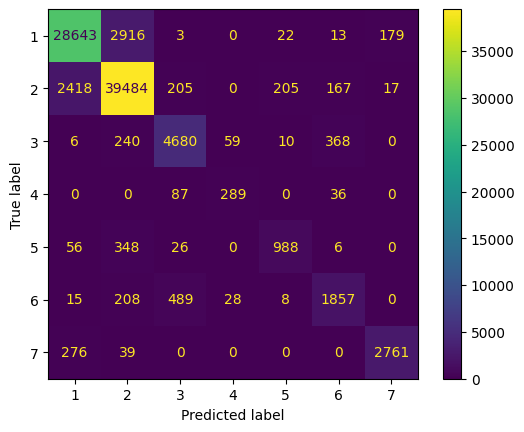

In [7]:
ConfusionMatrixDisplay.from_predictions(y_eval,knn_preds)

### Finding Best Params With RandomizedSearchCV for the KNN Model

In [20]:
from sklearn.model_selection import RandomizedSearchCV

In [21]:
tuned_knn_model=KNeighborsClassifier()  
ran_search_knn_model=RandomizedSearchCV(estimator=tuned_knn_model,param_distributions={'n_neighbors':np.arange(1,20,2),'weights':['uniform','distance'],'algorithm':['auto','ball_tree','kd_tree','brute']},n_iter=10,cv=5,scoring='f1_macro')
ran_search_knn_model.fit(decomposited_x_train_data,y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsClassifier()
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'algorithm': ['auto', 'ball_tree', ...], 'n_neighbors': array([ 1, 3..., 15, 17, 19]), 'weights': ['uniform', 'distance']}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versioncha

### Best Parameters That Found By RandomizedSearchCV :

In [28]:
ran_search_knn_model.best_params_

{'weights': 'distance', 'n_neighbors': np.int64(1), 'algorithm': 'ball_tree'}

In [29]:
knn_tuned_preds=ran_search_knn_model.predict(decomposited_x_eval_data)

In [30]:
print(classification_report(y_eval,knn_tuned_preds))

              precision    recall  f1-score   support

           1       0.92      0.92      0.92     31776
           2       0.93      0.93      0.93     42496
           3       0.88      0.88      0.88      5363
           4       0.78      0.71      0.75       412
           5       0.78      0.78      0.78      1424
           6       0.77      0.78      0.77      2605
           7       0.93      0.92      0.93      3076

    accuracy                           0.91     87152
   macro avg       0.86      0.85      0.85     87152
weighted avg       0.91      0.91      0.91     87152



RandomizedSearchCV improved the KNN model's Macro F1-score and Accuracy by approximately 1% compared to its default configuration.

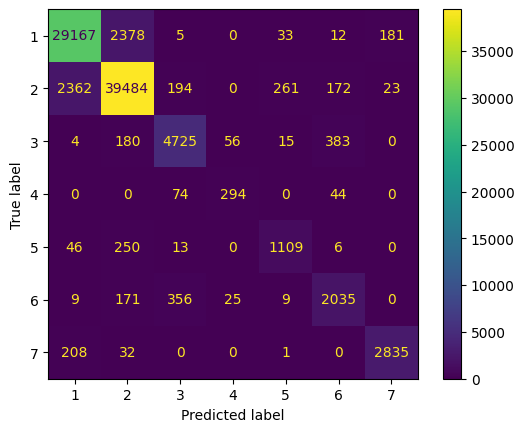

In [34]:
ConfusionMatrixDisplay.from_predictions(y_eval,knn_tuned_preds)

### Hyperparameter Tuning for the Random Forest Model

### Defualt Results :

In [2]:
from sklearn.ensemble import RandomForestClassifier

In [5]:
ran_model=RandomForestClassifier()
ran_model.fit(decomposited_x_train_data,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [6]:
ran_preds=ran_model.predict(decomposited_x_eval_data)

In [9]:
print(classification_report(y_eval,ran_preds))

              precision    recall  f1-score   support

           1       0.95      0.93      0.94     31776
           2       0.94      0.96      0.95     42496
           3       0.91      0.94      0.93      5363
           4       0.87      0.74      0.80       412
           5       0.91      0.76      0.83      1424
           6       0.89      0.84      0.86      2605
           7       0.97      0.93      0.95      3076

    accuracy                           0.94     87152
   macro avg       0.92      0.87      0.89     87152
weighted avg       0.94      0.94      0.94     87152



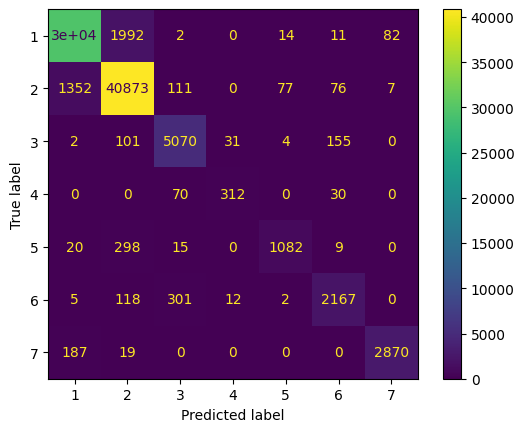

In [26]:
ConfusionMatrixDisplay.from_predictions(y_eval,ran_preds)

### Finding Best Params With RandomizedSearchCV for the Random Forest Model

In [36]:
tuned_ran_model=RandomForestClassifier()
ran_search_rf_model=RandomizedSearchCV(estimator=tuned_ran_model,param_distributions={'n_estimators':np.arange(50,200,10),'max_depth':np.arange(1,50),'min_samples_split':np.arange(1,20,2),'min_samples_leaf':np.arange(1,10,2),'max_features':['sqrt', 'log2', 0.5],'class_weight':[	None, 'balanced']},n_iter=10,cv=5,scoring='f1_macro')
ran_search_rf_model.fit(decomposited_x_train_data,y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestClassifier()
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'class_weight': [None, 'balanced'], 'max_depth': array([ 1, 2..., 47, 48, 49]), 'max_features': ['sqrt', 'log2', ...], 'min_samples_leaf': array([1, 3, 5, 7, 9]), ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation

In [37]:
ran_search_rf_model.best_params_

{'n_estimators': np.int64(90),
 'min_samples_split': np.int64(19),
 'min_samples_leaf': np.int64(1),
 'max_features': 'sqrt',
 'max_depth': np.int64(44),
 'class_weight': 'balanced'}

In [38]:
rf_tuned_preds=ran_search_rf_model.predict(decomposited_x_eval_data)

In [39]:
print(classification_report(y_eval,rf_tuned_preds))

              precision    recall  f1-score   support

           1       0.94      0.92      0.93     31776
           2       0.94      0.94      0.94     42496
           3       0.88      0.93      0.90      5363
           4       0.79      0.83      0.81       412
           5       0.80      0.83      0.82      1424
           6       0.79      0.86      0.82      2605
           7       0.92      0.95      0.93      3076

    accuracy                           0.93     87152
   macro avg       0.87      0.89      0.88     87152
weighted avg       0.93      0.93      0.93     87152



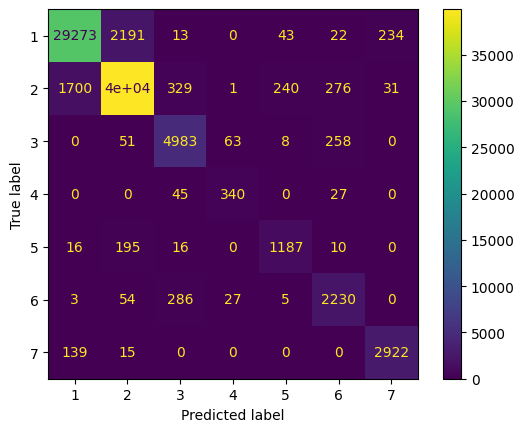

In [40]:
ConfusionMatrixDisplay.from_predictions(y_eval,rf_tuned_preds)

### Hyperparameter Tuning for the Gradient Boosting Model

In [41]:
from sklearn.ensemble import GradientBoostingClassifier
gb_model=GradientBoostingClassifier()
gb_model.fit(decomposited_x_train_data,y_train)

,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are'friedman_mse' for the mean squared error with improvement score byFriedman, 'squared_error' for mean squared error. The default value of'friedman_mse' is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, 

In [42]:
gb_preds=gb_model.predict(decomposited_x_eval_data)

In [43]:
print(classification_report(y_eval,gb_preds))

              precision    recall  f1-score   support

           1       0.75      0.72      0.74     31776
           2       0.77      0.83      0.80     42496
           3       0.71      0.83      0.77      5363
           4       0.70      0.59      0.64       412
           5       0.78      0.21      0.33      1424
           6       0.59      0.36      0.45      2605
           7       0.82      0.66      0.73      3076

    accuracy                           0.76     87152
   macro avg       0.73      0.60      0.64     87152
weighted avg       0.76      0.76      0.75     87152



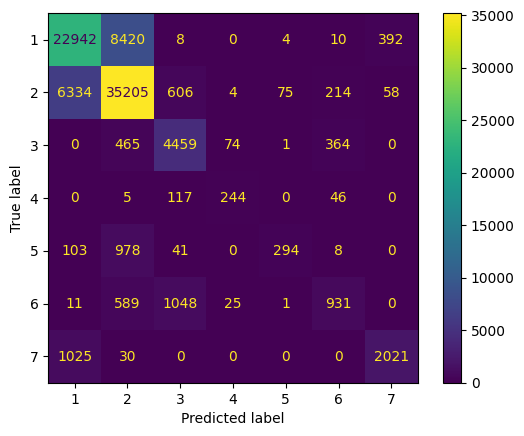

In [44]:
ConfusionMatrixDisplay.from_predictions(y_eval,gb_preds)

### Gradient Boosting – Exclusion from Hyperparameter Tuning

Gradient Boosting was not selected for hyperparameter tuning due to its considerably high computational cost and long training time. In its default configuration, the model also demonstrated lower performance compared to the other evaluated algorithms. Considering the trade-off between computational efficiency and predictive performance, further optimization was not deemed worthwhile within the scope of this project. Therefore, Gradient Boosting was retained with its default hyperparameters for the final comparative evaluation.

### Final Model Selection – Random Forest

Random Forest was selected as the final model due to its superior overall performance among the evaluated algorithms. Even with its default hyperparameter configuration, it achieved the highest Accuracy and Macro F1-score compared to the other models. This indicates that the model not only provided strong overall predictive performance but also maintained a better balance across the seven target classes. Furthermore, its strong baseline results made additional hyperparameter tuning unnecessary for the final model selection. Therefore, Random Forest was chosen as the final model for this study.

In [10]:
joblib.dump(ran_model,r'../DATA/covertype/final_model.pkl')

['../DATA/covertype/final_model.pkl']